# Journal 3 - Fine-tuning on Vertex AI

Logbook, third part: from the dataset to the trained model. Base model: `Qwen/Qwen2.5-3B-Instruct`, chosen over the course's Phi-3-mini because our tickets are in French and English (Qwen is better in French) and it fits a T4 GPU in 4 bits. The method is LoRA on a 4-bit base model (QLoRA), run as a Kubeflow pipeline on Vertex AI Pipelines, with the course's reference settings as a starting point: 3 epochs, LoRA rank 8, alpha 16, dropout 0.05, learning rate 3e-4.

Everything here is replayed in the order it happened, from the logs kept in the bucket. Nothing was billed on GCP before step 3.

## Step 1 - Do our chats fit in the sequence length of the reference settings?

The reference pipeline cuts every training example at 512 tokens. An example is the whole chat: the instruction (identical every time), the ticket, and the JSON answer, rendered with the chat template of Qwen. If an example is cut, the JSON answer, which comes last, is the part lost. Before spending anything on a GPU, I measure the length in tokens of the 1922 train examples with the real tokenizer (local and free).

C:\Users\Vincent\GitHub\Vincent-20-100\data-ai-product-to-delivery-navy\finetuned_llm_classifier\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


instruction alone: 270 tokens
count    1922.0
mean      504.0
std        95.0
min       352.0
50%       495.0
90%       621.0
99%       816.0
max      1051.0
longer than 512 tokens: 790 of 1922


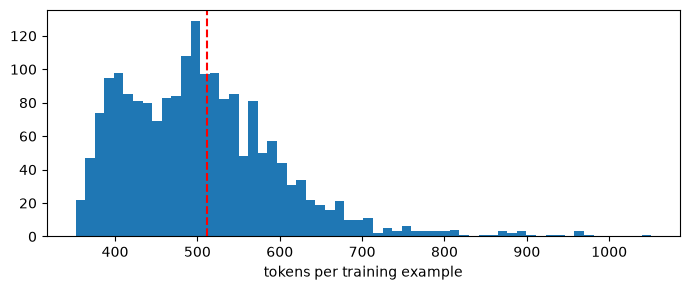

In [1]:
import csv, json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer
from src.prompt import INSTRUCTION, build_user_message

csv.field_size_limit(10**7)
tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-3B-Instruct")
train = pd.read_csv(ROOT / "data/dataset/train.csv", keep_default_na=False)
lengths = np.array([len(tok.apply_chat_template(
    [{"role": "user", "content": build_user_message(r.ticket)}, {"role": "assistant", "content": r.target}],
    tokenize=True)) for r in train.itertuples()])
print("instruction alone:", len(tok(INSTRUCTION)["input_ids"]), "tokens")
print(pd.Series(lengths).describe(percentiles=[.5, .9, .99]).round(0).to_string())
print("longer than 512 tokens:", int((lengths > 512).sum()), "of", len(lengths))
plt.figure(figsize=(7, 3)); plt.hist(lengths, bins=60); plt.axvline(512, color="red", ls="--"); plt.xlabel("tokens per training example")
plt.tight_layout()

## Step 2 - What does the loss learn from?

By default the loss is computed on every token of the example, so most of it would be spent learning to copy the instruction, which never changes. The answer is about 30 tokens out of 500. I want the loss on the assistant answer only. I check, with the library collator that does it, which tokens stay in the loss for three examples, and that the prompt used at inference time is exactly the beginning of the training text (otherwise training and inference would see different inputs).


**Reading.** The instruction alone is 270 tokens. The median example is 495 tokens, the 90th percentile 621 and the 99th 816; only one example is above 1024 (1051). **790 of the 1922 examples (41 percent) are longer than 512 tokens**, so with the reference setting the JSON answer would be cut off for four tickets out of ten, and those are mostly the long ones (forwarded threads, disclaimers). Decision: raise the maximum sequence length to 1024, which keeps all but one example whole. The price is memory: Qwen has a vocabulary of 152,000 tokens, so the logits of a batch grow quickly, which is why the batch becomes 2 with gradient accumulation of 2 (same effective batch of 4).


In [2]:
from trl import DataCollatorForCompletionOnlyLM
collator = DataCollatorForCompletionOnlyLM(response_template=tok.encode("<|im_start|>assistant\n", add_special_tokens=False), tokenizer=tok)
for r in list(train.itertuples())[:3]:
    messages = [{"role": "user", "content": build_user_message(r.ticket)}, {"role": "assistant", "content": r.target}]
    text = tok.apply_chat_template(messages, tokenize=False)
    batch = collator([{"input_ids": tok(text)["input_ids"]}])
    kept = [t for t in batch["labels"][0].tolist() if t != -100]
    print(len(batch["labels"][0]), "tokens in the example,", len(kept), "in the loss:", repr(tok.decode(kept)[:90]), "...")
prompt = tok.apply_chat_template(messages[:1], tokenize=False, add_generation_prompt=True)
print("inference prompt is the beginning of the training text:", text.startswith(prompt))

512 tokens in the example, 49 in the loss: '{"intent":"payment_status","sub_intent":"refund_status","transaction_id":"TX-520024","amou' ...
412 tokens in the example, 41 in the loss: '{"intent":"dispute","sub_intent":"unauthorised_fee","transaction_id":"","amount":"18.00","' ...
480 tokens in the example, 32 in the loss: '{"intent":"dispute","sub_intent":"amount_mismatch","transaction_id":"","amount":"","curren' ...
inference prompt is the beginning of the training text: True


**Reading.** In the three examples checked, only 32 to 49 tokens of 412 to 512 are in the loss, and they decode to the JSON answer (the check shows its first 90 characters). The loss is therefore computed on the answer alone. The prompt used at inference time is exactly the beginning of the training text, so the model sees the same input in training and in use. One more setting follows from this: examples are not packed together, so an answer is never split between two blocks.

Next: the first run on the GPU, kept very short.

## Step 3 - Smoke test, float32 (first billed run)

Nothing has run on the GPU yet, so the next run is a calibration: 200 tickets, 40 optimisation steps, then 20 predictions on val. It answers four questions: does everything load on a T4, how long does a step take (to estimate the full run), does the loss go down, and does the model already write valid JSON. The loss history is read back from the bucket, where the pipeline saved it with the adapter.

In [3]:
import sys
sys.path.insert(0, str(ROOT))
from google.cloud import storage
from src.constants import GCP_PROJECT_ID, GCP_BUCKET_NAME
from src import scoring

bucket = storage.Client(project=GCP_PROJECT_ID).bucket(GCP_BUCKET_NAME)

def history(job_id):
    blob = next(b for b in bucket.list_blobs(prefix="pipeline_root/") if job_id in b.name and b.name.endswith("log_history.json"))
    return pd.DataFrame(json.loads(blob.download_as_text()))

def smoke_score(csv_path):
    _, truths, _ = scoring.load_split(ROOT / "data/dataset/val.csv")
    preds = pd.read_csv(csv_path, keep_default_na=False)
    return scoring.score(truths[: len(preds)], list(preds["extracted_response"]))

h32 = history("20261101161625")
print("train runtime (s):", h32["train_runtime"].dropna().iloc[0])
display(h32.groupby("step")[["loss", "eval_loss", "grad_norm"]].first().dropna(how="all").round(4))
print({k: round(v, 3) for k, v in smoke_score(ROOT / "data/runs/smoke_predictions.csv").items()
       if k in ("n", "valid_json_rate", "desk_accuracy", "urgent_wrong_desk", "cost_per_ticket")})

train runtime (s): 654.504


,loss,eval_loss,grad_norm
step,,,
10,0.1664,NaN,0.6106
20,0.0701,0.0935,0.8070
30,0.0770,NaN,0.4115
40,0.0499,0.0855,0.2672


{'n': 20.0, 'valid_json_rate': 0.9, 'desk_accuracy': 0.9, 'urgent_wrong_desk': 0.0, 'cost_per_ticket': 0.7}



**Reading.** Everything loads and runs on the T4. 40 steps took 654.5 seconds, which is 16.4 seconds per optimisation step. The training loss falls from 0.166 to 0.050 and the validation loss from 0.0935 to 0.0855, the gradient norm stays between 0.27 and 0.81, and nothing is NaN. After these 40 steps on 200 tickets the model already writes valid JSON for 18 of the 20 val tickets (0.90) and finds the right desk for 18 (0.90), with no urgent ticket sent to a wrong desk; on 20 tickets this is only a sign that the pipeline works, not a score to compare with the baselines.

The speed is the problem. The full run is 1730 tickets (10 percent are kept for validation) over 3 epochs, about 1300 steps; at 16.4 seconds a step that is close to 6 hours of GPU, plus the periodic validation. Too long and too expensive for a first full run, and the course reference computes in float32 by habit.


## Step 4 - Smoke test, float16

Whatever the first run says about speed, the compute is in float32 because that is what the course reference does. A T4 has no bfloat16, but it does run float16 much faster. The risk of float16 is an unstable loss (NaN), so I repeat exactly the same smoke test with float16 compute and compare the loss values, the time and the predictions with the first run.

train runtime (s): float32 = 654.504 | float16 = 213.2938


C:\Users\Vincent\AppData\Local\Temp\ipykernel_19612\1647182496.py:4: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  display(curve(h32).join(curve(h16), lsuffix="_fp32", rsuffix="_fp16").round(4))


,loss_fp32,eval_loss_fp32,loss_fp16,eval_loss_fp16
step,,,,
10,0.1664,NaN,0.1663,NaN
20,0.0701,0.0935,0.0695,0.0898
30,0.0770,NaN,0.0740,NaN
40,0.0499,0.0855,0.0486,0.0797


{'n': 20.0, 'valid_json_rate': 0.95, 'desk_accuracy': 0.85, 'urgent_wrong_desk': 0.0, 'cost_per_ticket': 0.85}


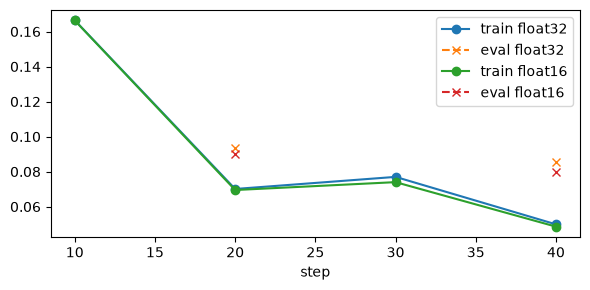

In [4]:
h16 = history("20261101170129")
print("train runtime (s): float32 =", h32["train_runtime"].dropna().iloc[0], "| float16 =", h16["train_runtime"].dropna().iloc[0])
curve = lambda h: h.groupby("step")[["loss", "eval_loss"]].first().dropna(how="all")
display(curve(h32).join(curve(h16), lsuffix="_fp32", rsuffix="_fp16").round(4))
fig, ax = plt.subplots(figsize=(6, 3))
for name, h in (("float32", h32), ("float16", h16)):
    c = curve(h)
    ax.plot(c.index, c["loss"], marker="o", label=f"train {name}")
    ax.plot(c.index, c["eval_loss"], marker="x", ls="--", label=f"eval {name}")
ax.set_xlabel("step"); ax.legend(); plt.tight_layout()
print({k: round(v, 3) for k, v in smoke_score(ROOT / "data/runs/smoke_fp16_predictions.csv").items()
       if k in ("n", "valid_json_rate", "desk_accuracy", "urgent_wrong_desk", "cost_per_ticket")})


**Reading.** The float16 run takes 213.3 seconds for the same 40 steps, 3.1 times faster than float32 (654.5). The losses stay very close at every step: 0.1663 against 0.1664 at step 10, 0.0695 against 0.0701 at step 20, 0.0740 against 0.0770 at step 30, 0.0486 against 0.0499 at step 40; the validation loss is 0.0898 and 0.0797 against 0.0935 and 0.0855. No NaN, and the gradient norms keep the same range. On the 20 predictions, valid JSON is 0.95 against 0.90 and the desk accuracy 0.85 against 0.90: it is one ticket each time, so it separates nothing.

Decision: the full run computes in float16. At about 5.3 seconds a step, the 1300 steps of three epochs take about two hours, plus the validation every 50 steps. Everything else stays as in the smoke tests.



## Step 5 - The full run (D: Qwen2.5-3B + LoRA)

Settings: float16, 3 epochs, LoRA rank 8, alpha 16, dropout 0.05, learning rate 3e-4, batch 2 with accumulation 2, sequences of 1024 tokens, loss on the answer only, the best checkpoint on validation loss kept. Predictions are made on val, not on the test sets (those are read once, at the end).

What I will look at, written before the result: first the loss curve (does the validation loss still fall at the end of the third epoch, or does it rise, which would mean overfitting), then the 293 val predictions scored with the protocol. The model passes this gate if valid JSON is at least 99 percent and the expected cost per ticket on val is not worse than B2's 1.478 (val value, with C = 10). If not, I diagnose by field before changing anything (epochs, learning rate), and only on val.


train runtime (s): 7568 | mean train loss: 0.0117
validation loss: best 0.00304 at step 1250 | last evaluation at step 1250


step,50,100,150,200,250,300,350,400,450,500,...,800,850,900,950,1000,1050,1100,1150,1200,1250
eval_loss,0.0454,0.0269,0.0183,0.0296,0.0096,0.0118,0.0108,0.0078,0.0075,0.0072,...,0.0048,0.0061,0.0063,0.0067,0.0048,0.0048,0.0042,0.004,0.0037,0.003


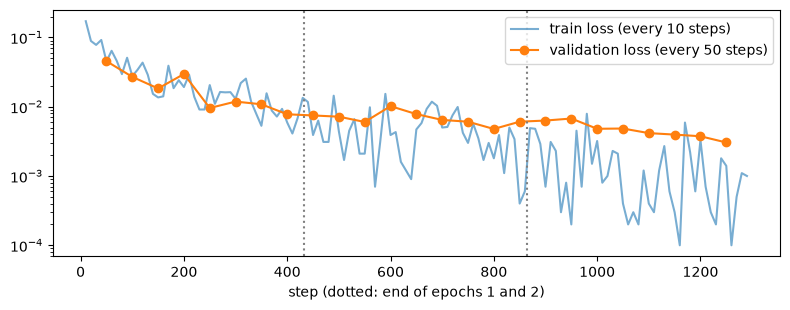

In [5]:
JOB = "20261101173631"
hf = history(JOB)
curve_full = hf.groupby("step")[["loss", "eval_loss"]].first()
print("train runtime (s):", round(hf["train_runtime"].dropna().iloc[0]), "| mean train loss:", round(hf["train_loss"].dropna().iloc[0], 4))
ev = curve_full["eval_loss"].dropna()
print("validation loss: best", round(ev.min(), 5), "at step", ev.idxmin(), "| last evaluation at step", ev.index[-1])
display(ev.rename("eval_loss").to_frame().T.round(4))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(curve_full.index, curve_full["loss"], label="train loss (every 10 steps)", alpha=.6)
ax.plot(ev.index, ev.values, marker="o", label="validation loss (every 50 steps)")
ax.axvline(432, color="grey", ls=":"); ax.axvline(864, color="grey", ls=":")
ax.set_yscale("log"); ax.set_xlabel("step (dotted: end of epochs 1 and 2)"); ax.legend(); plt.tight_layout()

**Reading.** The run took 7568 seconds, about 2 hours 6 minutes of GPU, as estimated from the float16 smoke test. The validation loss falls fast (0.045 at step 50, 0.027 at step 100), then oscillates between 0.005 and 0.007 through the second epoch, and falls again at the end of the third: its lowest value is 0.00304, at step 1250, the last evaluation. So it never rose durably and the checkpoint kept by the pipeline is the one at the end; there was nothing to cut. The oscillations in the middle of the run (a peak of 0.0067 at step 950) were noise, not the start of overfitting as I first read them while the run was going. The loss values are tiny because only the answer is in the loss and most of its tokens (keys, braces) are fixed.

This says the model fits the answers, not how well it reads the tickets. That is what the scoring tells.

## Step 6 - Scoring the 293 val predictions against the baselines

The pipeline's inference step wrote one prediction per val ticket, from the best checkpoint. I score them with the same scorer and the same tickets as B0, B1 and B2 on val (B2 with C = 10, fitted on train). The gate written before the run: valid JSON at least 99 percent, and a cost per ticket not worse than B2's on val. The test sets are not touched.

In [6]:
from src.baselines import predict_majority, predict_rules, fit_tfidf, predict_tfidf
val_x, val_y, _ = scoring.load_split(ROOT / "data/dataset/val.csv")
train_x, train_y, _ = scoring.load_split(ROOT / "data/dataset/train.csv")
full = pd.read_csv(ROOT / "data/runs/full_val_predictions.csv", keep_default_na=False)
assert list(full["user_input"]) == val_x
raw_d = list(full["extracted_response"])
SHOWN = ["valid_json_rate", "desk_accuracy", "urgent_wrong_desk", "confident_and_wrong", "abstention_rate", "macro_f1_intent",
         "exact_transaction_id", "exact_amount", "accuracy_urgency", "recall_high_urgency", "cost_per_ticket"]
systems = {"B1": scoring.score(val_y, predict_rules(val_x)),
           "B2": scoring.score(val_y, predict_tfidf(fit_tfidf(train_x, train_y, 10.0), val_x)),
           "D": scoring.score(val_y, raw_d)}
display(pd.DataFrame(systems).loc[SHOWN].round(3))
print("valid outputs:", round(systems["D"]["valid_json_rate"] * len(val_y)), "of", len(val_y),
      "| 99 percent needs", -(-99 * len(val_y) // 100))

,B1,B2,D
valid_json_rate,1.000,1.000,0.990
desk_accuracy,0.403,0.949,0.986
urgent_wrong_desk,0.392,0.076,0.000
confident_and_wrong,0.530,0.051,0.008
abstention_rate,0.266,0.137,0.157
macro_f1_intent,0.321,0.927,0.984
exact_transaction_id,0.894,0.894,0.986
exact_amount,0.829,0.829,0.990
accuracy_urgency,0.464,0.952,0.983
recall_high_urgency,0.203,0.911,0.975


valid outputs: 290 of 293 | 99 percent needs 291


**Reading.** D is far above B2 on val: cost per ticket 0.027 against 1.478 for B2, desk accuracy 0.986 against 0.949, no urgent ticket in a wrong desk (B2: 0.076), macro-F1 on intent 0.984 against 0.927. The reference fields are where it differs most from the baselines, which share one set of regular expressions: exact match 0.986 for the id and 0.990 for the amount, against 0.894 and 0.829. Urgency accuracy is 0.983 against 0.952 and recall on urgent tickets 0.975 against 0.911.

On the gate itself, valid JSON is 0.9898: **290 outputs of 293 are valid, and 99 percent needs 291**, so on val the model misses the 99 percent criterion by one ticket. The cost gate is passed by a wide margin.

Two cautions before reading too much into the gap with B2. Val has the same writer and the same kind of tickets as train, so the model may be reading the style of that writer; the tests written by another model are the real check, and I do not look at them yet. And 293 tickets is small, so the 99 percent line is decided by one or two outputs. Next: look at the three invalid outputs and at the remaining errors, field by field.

## Step 7 - What are the three invalid outputs, and what else is wrong?

An output is invalid when it is not a JSON object of the contract. I print the three, with the label of the ticket, and count the errors of the valid outputs per field.

In [7]:
from collections import Counter
bad = [(i, r) for i, r in enumerate(full.itertuples()) if scoring.parse_output(r.extracted_response) is None]
for i, r in bad:
    print(i, "model :", {k: v for k, v in json.loads(r.extracted_response).items() if k in ("transaction_id", "intent", "sub_intent")})
    print("  truth:", {k: v for k, v in val_y[i].model_dump().items() if k in ("transaction_id", "intent", "sub_intent")})
errors = Counter()
for truth, raw in zip(val_y, raw_d):
    pred = scoring.parse_output(raw)
    if pred:
        for field, value in truth.model_dump().items():
            errors[field] += getattr(pred, field) != value
print("errors among the valid outputs, per field:", dict(errors))

29 model : {'intent': 'dispute', 'sub_intent': 'duplicate_charge', 'transaction_id': 'TX-6084'}
  truth: {'intent': 'dispute', 'sub_intent': 'duplicate_charge', 'transaction_id': 'UNDEFINED'}
113 model : {'intent': 'UNDEFINED', 'sub_intent': 'UNDEFINED', 'transaction_id': 'TX-7864'}
  truth: {'intent': 'UNDEFINED', 'sub_intent': 'UNDEFINED', 'transaction_id': 'UNDEFINED'}
223 model : {'intent': 'payment_status', 'sub_intent': 'missing_payment', 'transaction_id': 'TX-89928'}
  truth: {'intent': 'payment_status', 'sub_intent': 'missing_payment', 'transaction_id': ''}
errors among the valid outputs, per field: {'intent': 2, 'sub_intent': 4, 'transaction_id': 1, 'amount': 0, 'currency': 0, 'urgency': 2, 'sentiment': 1}


**Reading.** The three invalid outputs are not broken JSON. In each one the model copied a malformed transaction id from the ticket (`TX-6084`, `TX-7864`, `TX-89928`, with 4 or 5 digits instead of 6), while the contract says an id is `TX-` and six digits, and the label is `UNDEFINED` (twice) or empty. The contract rejects the output, so it counts as invalid and goes to a human. This is the `id_malformed` trap of the dataset: the model has not fully learned to answer `UNDEFINED` when an id looks like one but is not.

Among the 290 valid outputs the remaining errors are few: 4 on `sub_intent`, 2 on `intent`, 2 on urgency, 1 on sentiment, 1 on the id. So the gap between D and the baselines does not come from one field.

**State at the end of this journal.** The full run is done and cost about 2 hours of T4 for training plus 30 minutes of inference. On val, D passes the cost gate by far and misses the valid-JSON gate by one ticket, because of malformed ids copied from the ticket. The test sets have not been read. Next: the light variants (merged then 4-bit GGUF on CPU, a smaller model), then the single reading of the tests, with the efficiency metric written into the protocol first.